# Session 118 - Full Rag implementation 

This part we will use the embedding created in previous section - Rag_embedding.ipynb file to proceed.

In previous ipynb we created embedding for our knowledge base using Huggingface (all-MiniLM-L6-v2) and stored in Chroma vector DB

In [1]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

from langchain_chroma import Chroma
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_huggingface import HuggingFaceEmbeddings
import gradio as gr

/home/codespace/.local/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
MODEL = "gpt-4.1-nano"
DB_NAME = "vector_db" # we have created this in last RAG_embedding.ipynb
load_dotenv(override=True)

True

In previous we used vectorstore = Chroma.from_documents(documents=chunks, embedding=embeddings, persist_directory=db_name)
 to create vectorstore for embedding of our Document, and we saved that as db_name.

Syntax :
-Chroma.from_documents() - creates/populates a vector store from documents


-Chroma() connects to an existing vector store.

In [3]:
# Connect to Chroma; use Hugging Face all-MiniLM-L6-v2


embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
vectorstore = Chroma(persist_directory=DB_NAME, embedding_function=embeddings)

Loading weights: 100%|██████████| 103/103 [00:01<00:00, 92.20it/s]


## Set up the 2 key LangChain objects: retriever and llm

In [4]:
# set up LLM
llm = ChatOpenAI(temperature=0, model_name=MODEL)

# set up retreiver 
retriever = vectorstore.as_retriever()

## Invoking using both Objects separately

- Invoking using retriever - We know retriever now acts as an interface to the vector db with our whole documents . So doing a query (invoke) will give the most relevant/matching Documents from our vector store.

- invoking using llm - it will do a normal llm query on its existing knowledge (not on our knoledge )



In [5]:
retriever.invoke("Who is Shari?")

[Document(id='ec0acdc2-dbc4-49f4-a9ec-7979c2b4ef0b', metadata={'source': 'knowledge_base/Shari_Professional.md'}, page_content='Shari is currently working as a Junior Developer at AITrich, located at Infopark, Kochi, Kerala. Her present career focus is on developing her capabilities as an AI-oriented software developer while strengthening her understanding of modern programming frameworks and artificial intelligence technologies.'),
 Document(id='50ca2f7d-b7e0-47ec-8ac5-f688cf37f10a', metadata={'source': 'knowledge_base/Shari_Professional.md'}, page_content="Shari's career is characterized by her ability to move between different professional roles and continue learning. Her journey from college lecturer to data scientist and junior AI developer demonstrates her willingness to expand her skills and adapt to new technologies."),
 Document(id='b9c99e09-7d62-4c98-bb71-1932f33c5754', metadata={'source': 'knowledge_base/family/shari/shari_parents.md'}, page_content="## Shari Parents \nShari

In [6]:
llm.invoke("Who is Shari?")

AIMessage(content='"Shari" can refer to various individuals or entities, depending on the context. Could you please provide more details or specify which Shari you are referring to?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 12, 'total_tokens': 45, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-nano-2025-04-14', 'system_fingerprint': 'fp_3d5d379115', 'id': 'chatcmpl-Ea4e2wx3rXxsoRpKue9H0MkLoPQGa', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14b66-76cb-7991-98bc-63ce8e0d544b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 12, 'output_tokens': 33, 'total_tokens': 45, 'input_token_details': {'audio': 0, 'cache_read':

## Time to put this together!

Remember we did a similar code in KrishNaik project - https://github.com/tonu1990-ai/GenAI_KN/blob/main/langchain/genai_project_1.ipynb

Check section 1. Retriever

In that we created a Vector store retriever for Chroma as chroma_retriever =chroma_db.as_retriever()
Then 
from langchain_classic.chains import create_retrieval_chain

chroma_retrieval_chain = create_retrieval_chain(chroma_retriever,document_chain) , 
where document_chain = create_stuff_documents_chain(llm,my_prompt)

In [7]:
SYSTEM_PROMPT_TEMPLATE = """
You are a knowledgeable, personal profile chatbot for a couple Mr.Tonu James and Mrs.Shari Thomas.
You are chatting with a user about Tonu and Shari.
If relevant, use the given context to answer any question.
If you don't know the answer, say so.
Context:
{context}
"""

# Define how do we do LLM call with context and prompt 

- first we take relevant documents for our query using already discussed retriever.invoke("Who is Shari?")

- then the matching docs are combined into "context"

- then the context is formated into prompt we defined 

- then we query LLM using SystemMessage = prompt and HumanMessage = our actula question

In [18]:
def answer_question(question: str, history):
    docs = retriever.invoke(question)
    context = "\n\n".join(doc.page_content for doc in docs)
    system_prompt = SYSTEM_PROMPT_TEMPLATE.format(context=context)
    response = llm.invoke([SystemMessage(content=system_prompt), HumanMessage(content=question)])
    return response.content

### Answers might not be accurate .

In [19]:
answer_question("Who Shari?", [])

'Shari Thomas is a technology professional currently working as a Junior Developer at AITrich in Kochi, Kerala. She has a diverse background that includes experience in higher education, software development, data science, and artificial intelligence. Shari is known for her ability to adapt and learn new skills, moving from being a college lecturer to a data scientist and AI developer. She is dedicated to expanding her expertise in modern programming frameworks and AI technologies.'

In [21]:
answer_question("Who Tonu?",[])

'Tonu James is a software and artificial intelligence professional with a background in Computer Science, Engineering, and Image Processing. He was born on March 8, 1990, in Kanhangad, Kerala, India, and now resides in Kolenchery with his family. He has a strong academic background, including a B.Tech in Computer Science and Engineering and an M.Tech in Image Processing. He is married to Mrs. Shari Thomas, and they have three children together.'

In [11]:
# query with a typo
answer_question("Who Tony?", [])

'It seems like you might be referring to "Tonu," who is Mr. Tonu James. He is one of the individuals I am here to tell you about. If you meant someone else or have more specific questions about Tonu James, please let me know!'

we will create a Gradio UI. 
Note : Though we pass history to answer_question(question: str, history), it doesnt use it in LLM querying. So our chatbot is kind of stateless. This is an issues with our current project. See the chatbot response below

In [ ]:
gr.ChatInterface(answer_question).launch()

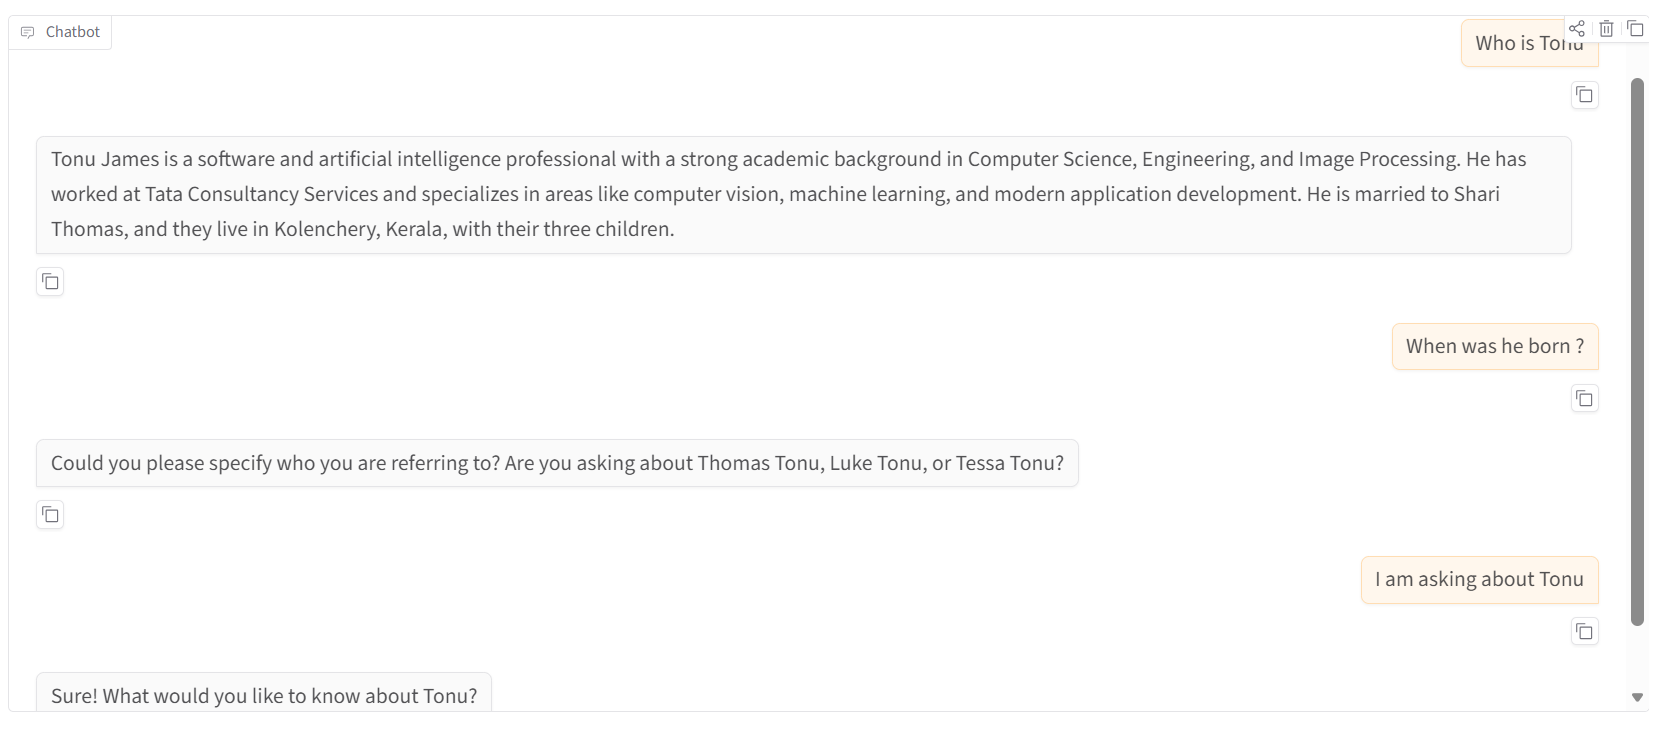

Additional Notes :

- In this code we have used from langchain_openai import ChatOpenAI
 as our LLM and used llm = ChatOpenAI(temperature=0, model_name=MODEL) where model = "gpt-4.1-nano"

 - we could have also used other llm interface available in langchain as ;
 
 from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="llama3.2"
)


-But there is another concept called OpenAI-compatible APIs. Which means many LLM-serving platforms have adopted API request and response formats compatible with OpenAI.
For example, Ollama supports an OpenAI-compatible Chat Completions endpoint. 
-This means we can use ChatOpenAI to communicate with Ollama instead of OpenAI.

example :

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="llama3.2",
    base_url="http://localhost:11434/v1",
    api_key="ollama"
)